# 02 · Classical computer-vision baseline

**Question:** how well can handcrafted features separate 196 fine-grained car classes, and which feature families contribute most?

This covers the P5 classical requirements: preprocessing, edges and contours, colour and texture features, ROI extraction and geometric analysis. It also produces the classical side of the classical vs deep vs hybrid comparison.

**Method**
- Cars are cropped with the annotated box plus an 8% margin, the same crops the deep model uses, so this measures classification only. Detector crops are evaluated separately.
- All choices are made on the validation split. The test split is used once, in the final section.

In [1]:
import json, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "backend").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "backend"))
import os
os.environ["PYTHONPATH"] = str(ROOT / "backend")

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix, top_k_accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from classical_cv import feature_blocks, run_pipeline
from classical_cv.batch import compute_features
from data.stanford_cars import box_with_margin, default_root, load_class_names, load_manifest

DATA = default_root()
CACHE = DATA.parent / "features"
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
INK, MUTED, BAR = "#15202A", "#55646F", "#0B6E99"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED, "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})

manifest = load_manifest()
classes = load_class_names()
print(manifest["split"].value_counts().to_dict(), "classes:", len(classes))
print("Feature blocks:", feature_blocks())

{'test': 8041, 'train': 6922, 'val': 1222} classes: 196
Feature blocks: {'hsv': 32, 'lbp': 160, 'hog': 1764, 'geometry': 12}


## Dataset verification

`scripts/prepare_dataset.py` stops unless these checks pass. They're repeated here so the evidence stays in the notebook.

In [2]:
print(json.dumps(json.loads((DATA / "verification.json").read_text()), indent=2))

{
  "test_annotations_md5": "b0a2b23655a3edd16d84508592a98d10",
  "splits": {
    "train": {
      "rows": 8144,
      "boxes_inside_image": 8144,
      "boxes_inside_image_if_shuffled": 0.5365
    },
    "test": {
      "rows": 8041,
      "boxes_inside_image": 8041,
      "boxes_inside_image_if_shuffled": 0.5341
    }
  },
  "final_split_sizes": {
    "test": 8041,
    "train": 6922,
    "val": 1222
  },
  "val_fraction": 0.15,
  "seed": 42
}


## Classes per split

The split is stratified, so validation keeps the same class balance as train.

split  test  train
min      24     20
50%      42     36
max      68     58


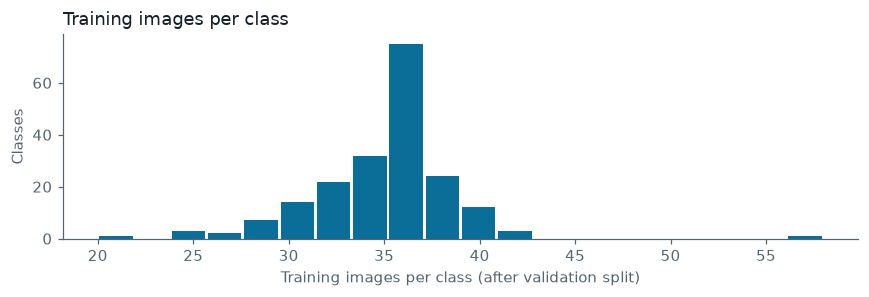

In [3]:
counts = manifest[manifest.split != "val"].groupby(["split", "label"]).size().unstack(0)
print(counts.describe().loc[["min", "50%", "max"]].round(0).astype(int).to_string())
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(counts["train"], bins=20, color=BAR, rwidth=.92)
ax.set_xlabel("Training images per class (after validation split)"); ax.set_ylabel("Classes")
ax.set_title("Training images per class", loc="left")
plt.tight_layout(); plt.savefig(FIGURES / "train_images_per_class.png"); plt.show()

## Pipeline stages on a real image

These are the same stages the app shows through `run_pipeline`.

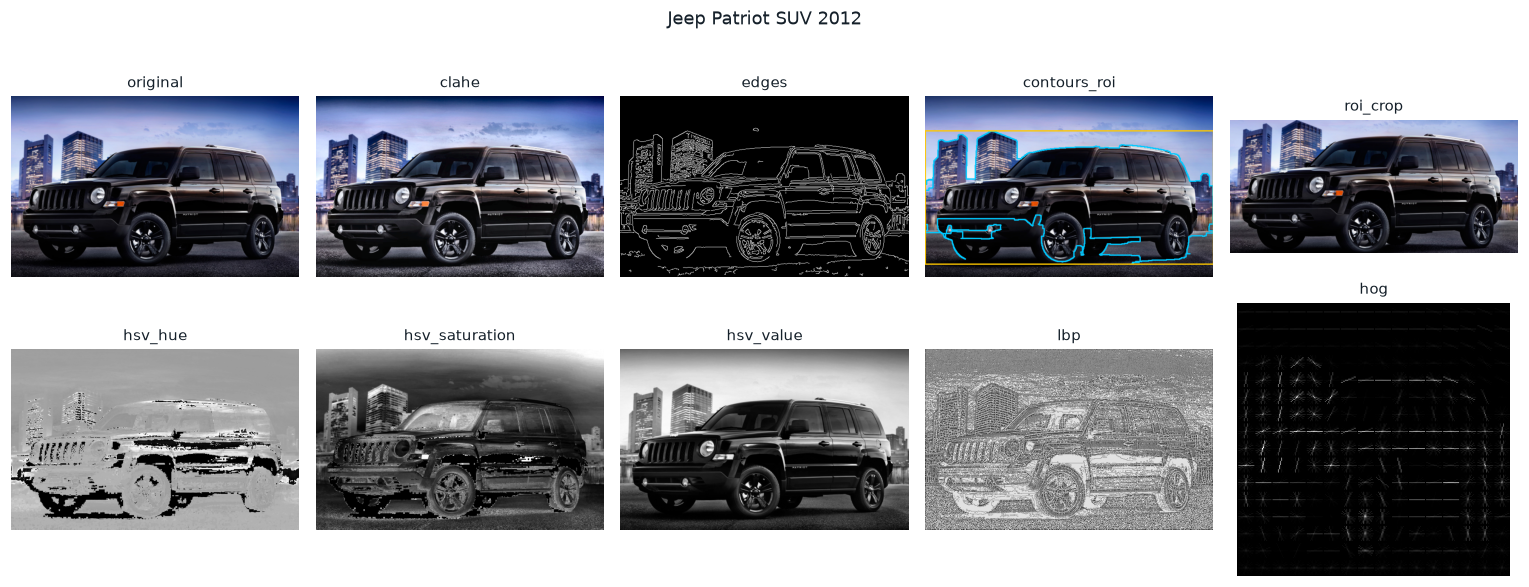

low light: False | mean luma: 77.1 | ROI: (0, 76, 640, 372)
{'aspect_ratio': 2.162, 'extent': 0.658, 'solidity': 0.77, 'area_fraction': 0.487, 'edge_density': 0.085, 'hu_1': 0.559, 'hu_2': 1.348, 'hu_3': 3.417, 'hu_4': 3.588, 'hu_5': 7.097, 'hu_6': 4.279, 'hu_7': 7.857}


In [4]:
sample = manifest[manifest.split == "train"].sample(1, random_state=3).iloc[0]
result = run_pipeline(cv2.imread(str(DATA / sample.path)))
fig, axes = plt.subplots(2, 5, figsize=(14, 5.4))
for axis, (name, view) in zip(axes.ravel(), result.images.items()):
    shown = cv2.cvtColor(view, cv2.COLOR_BGR2RGB) if view.ndim == 3 else view
    axis.imshow(shown, cmap=None if view.ndim == 3 else "gray"); axis.set_title(name, fontsize=10); axis.axis("off")
fig.suptitle(sample.class_name); plt.tight_layout(); plt.savefig(FIGURES / "classical_stages.png"); plt.show()
print("low light:", result.low_light, "| mean luma:", round(result.mean_luma, 1), "| ROI:", result.roi)
print({key: round(value, 3) for key, value in result.geometry.items()})

## Feature extraction

Features are computed for all 16,185 images and cached on disk.

In [5]:
started = time.perf_counter()
features = compute_features(manifest, DATA, CACHE / "classical_crop8.npy", enhance=False)
print(features.shape, f"{time.perf_counter() - started:.0f}s (near zero means the cache was used)")
masks = {split: (manifest["split"] == split).to_numpy() for split in ("train", "val", "test")}
labels = manifest["label"].to_numpy()
blocks, start = {}, 0
for name, length in feature_blocks().items():
    blocks[name] = np.arange(start, start + length); start += length
assert start == features.shape[1]

(16185, 1968) 0s (near zero means the cache was used)


## Which feature families matter? (validation)

Each family alone, and all together. Each model is standardised, reduced with PCA where the family is large, and classified with a linear SVM. This is also the classical part of the ablation study.

{'features': 'hsv', 'dimensions': 32, 'top1': 0.031096563011456628, 'top5': 0.1039279869067103, 'fit_seconds': 5.1}


{'features': 'lbp', 'dimensions': 160, 'top1': 0.04091653027823241, 'top5': 0.13829787234042554, 'fit_seconds': 47.0}


{'features': 'hog', 'dimensions': 1764, 'top1': 0.14402618657937807, 'top5': 0.3150572831423895, 'fit_seconds': 81.4}


{'features': 'geometry', 'dimensions': 12, 'top1': 0.014729950900163666, 'top5': 0.05319148936170213, 'fit_seconds': 4.0}


{'features': 'all', 'dimensions': 1968, 'top1': 0.16775777414075285, 'top5': 0.337152209492635, 'fit_seconds': 75.2}


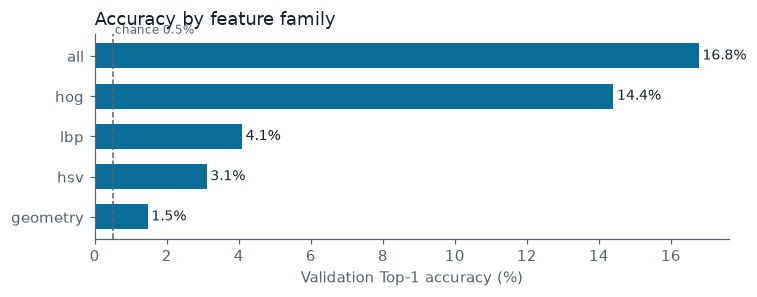

In [6]:
def make_model(n_features, C=0.01):
    steps = [StandardScaler()]
    if n_features > 256:
        steps.append(PCA(256, random_state=42))
    steps.append(LinearSVC(C=C, dual=False, max_iter=2000, random_state=42))
    return make_pipeline(*steps)

def score(model, X, y):
    decision = model.decision_function(X)
    return {"top1": float(top_k_accuracy_score(y, decision, k=1, labels=np.arange(196))), "top5": float(top_k_accuracy_score(y, decision, k=5, labels=np.arange(196)))}

family_rows = []
for name, columns in {**blocks, "all": np.arange(features.shape[1])}.items():
    begun = time.perf_counter()
    model = make_model(len(columns)).fit(features[masks["train"]][:, columns], labels[masks["train"]])
    row = {"features": name, "dimensions": len(columns), **score(model, features[masks["val"]][:, columns], labels[masks["val"]]), "fit_seconds": round(time.perf_counter() - begun, 1)}
    family_rows.append(row); print(row)
families = pd.DataFrame(family_rows)
chance = 1 / 196
fig, ax = plt.subplots(figsize=(7, 2.8))
ordered = families.sort_values("top1")
ax.barh(ordered["features"], ordered["top1"] * 100, color=BAR, height=.62)
for y, value in enumerate(ordered["top1"] * 100):
    ax.text(value + .1, y, f"{value:.1f}%", va="center", fontsize=9, color=INK)
ax.axvline(chance * 100, color=MUTED, linewidth=1, linestyle="--"); ax.text(chance * 100 + .05, len(ordered) - .45, "chance 0.5%", fontsize=8, color=MUTED)
ax.set_xlabel("Validation Top-1 accuracy (%)"); ax.set_title("Accuracy by feature family", loc="left")
plt.tight_layout(); plt.savefig(FIGURES / "classical_families.png"); plt.show()

## Tuning (validation)

Regularisation strength is chosen on validation only.

In [7]:
all_columns = np.arange(features.shape[1])
tuning = []
for C in (0.001, 0.01, 0.1):
    model = make_model(len(all_columns), C).fit(features[masks["train"]], labels[masks["train"]])
    tuning.append({"C": C, **score(model, features[masks["val"]], labels[masks["val"]])}); print(tuning[-1])
best_C = max(tuning, key=lambda row: row["top1"])["C"]
print("Chosen C:", best_C)

{'C': 0.001, 'top1': 0.15548281505728315, 'top5': 0.34942716857610473}


{'C': 0.01, 'top1': 0.16775777414075285, 'top5': 0.337152209492635}


{'C': 0.1, 'top1': 0.12274959083469722, 'top5': 0.3011456628477905}
Chosen C: 0.01


## Does CLAHE on dark images help? (validation)

`adaptive_enhance` applies CLAHE only when mean brightness is low. This is tested rather than assumed.

In [8]:
enhanced = compute_features(manifest, DATA, CACHE / "classical_crop8_enhanced.npy", enhance=True)
plain_val = max(tuning, key=lambda row: row["top1"])
enhanced_model = make_model(len(all_columns), best_C).fit(enhanced[masks["train"]], labels[masks["train"]])
enhanced_val = score(enhanced_model, enhanced[masks["val"]], labels[masks["val"]])
print("without:", {k: round(plain_val[k], 4) for k in ("top1", "top5")}, "| with adaptive CLAHE:", {k: round(v, 4) for k, v in enhanced_val.items()})
use_enhanced = enhanced_val["top1"] > plain_val["top1"]
print("Using adaptive CLAHE for the final model:", use_enhanced)

without: {'top1': 0.1678, 'top5': 0.3372} | with adaptive CLAHE: {'top1': 0.1645, 'top5': 0.3445}
Using adaptive CLAHE for the final model: False


## Final evaluation on the unseen test set

The chosen model is refit on train + validation and scored on the test split. This cell is run once.

In [9]:
final_features = enhanced if use_enhanced else features
development = masks["train"] | masks["val"]
final_model = make_model(final_features.shape[1], best_C).fit(final_features[development], labels[development])
started = time.perf_counter()
decision = final_model.decision_function(final_features[masks["test"]])
predict_ms = (time.perf_counter() - started) / masks["test"].sum() * 1000
y_test = labels[masks["test"]]
predictions = decision.argmax(1)
test_scores = {"top1": float((predictions == y_test).mean()), "top5": float(top_k_accuracy_score(y_test, decision, k=5, labels=np.arange(196)))}
print(test_scores, f"(chance: Top-1 {1/196:.4f}, Top-5 {5/196:.4f})")

{'top1': 0.17323715955726898, 'top5': 0.3681134187290138} (chance: Top-1 0.0051, Top-5 0.0255)


## Per-class results and most-confused pairs

Macro F1: 0.1585

Best classes:
                                      precision  recall  f1-score  support
Dodge Ram Pickup 3500 Crew Cab 2010      0.274   0.476     0.348     42.0
BMW X3 SUV 2012                          0.387   0.316     0.348     38.0
smart fortwo Convertible 2012            0.253   0.600     0.356     40.0
FIAT 500 Abarth 2012                     0.355   0.407     0.379     27.0
Dodge Sprinter Cargo Van 2009            0.301   0.564     0.393     39.0
Chevrolet HHR SS 2010                    0.360   0.500     0.419     36.0
Mercedes-Benz Sprinter Van 2012          0.333   0.610     0.431     41.0
AM General Hummer SUV 2000               0.303   0.750     0.431     44.0

Worst classes:
                                         precision  recall  f1-score  support
Acura RL Sedan 2012                           0.0     0.0       0.0     32.0
Audi S5 Coupe 2012                            0.0     0.0       0.0     42.0
Chevrolet Impala Sedan 2007                   0.0    

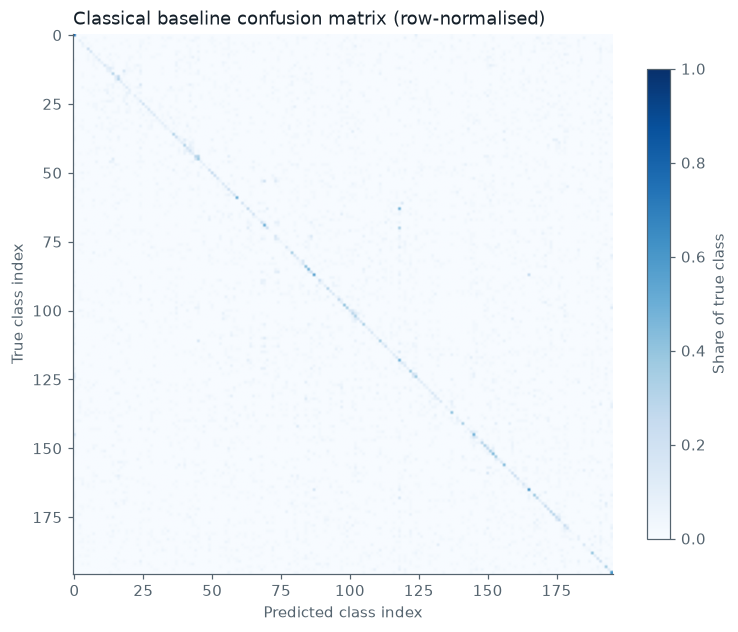

In [10]:
report = classification_report(y_test, predictions, labels=np.arange(196), target_names=classes, output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.loc[classes][["precision", "recall", "f1-score", "support"]]
print("Macro F1:", round(report["macro avg"]["f1-score"], 4))
print("\nBest classes:\n", per_class.sort_values("f1-score").tail(8).round(3).to_string())
print("\nWorst classes:\n", per_class.sort_values("f1-score").head(8).round(3).to_string())
matrix = confusion_matrix(y_test, predictions, labels=np.arange(196))
off = matrix.copy(); np.fill_diagonal(off, 0)
pairs = [{"true": classes[i], "predicted": classes[j], "count": int(off[i, j])} for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1][:10], off.shape))]
print("\n", pd.DataFrame(pairs).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(matrix / matrix.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
ax.set_xlabel("Predicted class index"); ax.set_ylabel("True class index"); ax.set_title("Classical baseline confusion matrix (row-normalised)", loc="left")
fig.colorbar(image, shrink=.8, label="Share of true class"); plt.tight_layout(); plt.savefig(FIGURES / "classical_confusion.png"); plt.show()

## Size and speed

Time covers feature extraction and classification for one image on this laptop's CPU (Intel i5-1135G7), including image loading.

In [11]:
from classical_cv import extract_features
model_dir = DATA.parent / "models"; model_dir.mkdir(exist_ok=True)
model_path = model_dir / "classical_baseline.joblib"; joblib.dump(final_model, model_path)
timing_rows = manifest[manifest.split == "test"].sample(100, random_state=0)
started = time.perf_counter()
for row in timing_rows.itertuples():
    x1, y1, x2, y2 = box_with_margin(row)
    picture = cv2.imread(str(DATA / row.path))[y1:y2, x1:x2]
    final_model.decision_function(extract_features(picture, enhance=use_enhanced)[None])
per_image_ms = (time.perf_counter() - started) / len(timing_rows) * 1000
size_mb = model_path.stat().st_size / 1e6
print(f"Per image: {per_image_ms:.1f} ms | model file: {size_mb:.1f} MB")

Per image: 14.8 ms | model file: 2.5 MB


## Save results

The app and `eval_P5_<TeamID>.md` read this file, so no number is typed by hand.

In [12]:
output = {
    "experiment": "classical_baseline",
    "model": "StandardScaler + PCA(256) + LinearSVC on HSV, LBP, HOG and geometric features",
    "crop": "annotated box + 8% margin",
    "fit_on": "train + val", "evaluated_on": "test", "test_images": int(masks["test"].sum()),
    "chosen_C": best_C, "adaptive_clahe": bool(use_enhanced),
    "test": {**test_scores, "macro_f1": report["macro avg"]["f1-score"], "macro_precision": report["macro avg"]["precision"], "macro_recall": report["macro avg"]["recall"]},
    "validation_by_family": family_rows, "validation_tuning": tuning,
    "validation_clahe": {"without": {k: plain_val[k] for k in ("top1", "top5")}, "with": enhanced_val},
    "per_image_ms_cpu": per_image_ms, "model_size_mb": size_mb, "cpu": "Intel i5-1135G7",
    "most_confused": pairs,
    "per_class": per_class.round(4).reset_index(names="class").to_dict("records"),
}
(RESULTS / "classical_baseline.json").write_text(json.dumps(output, indent=2), encoding="utf-8")
print("Saved", RESULTS / "classical_baseline.json")

Saved C:\Users\Arpita\AppData\Local\Claude-Data\claude_pzs8sxrjxfjjc\scratch-workspaces\7b690baa-02e8-4a88-890f-002d23b2a964\db9f70f9-43d5-4973-a4b0-6d18a98dbec2\scratch-2026-11-06-15a841\results\classical_baseline.json


## Findings

These summarise the outputs above.

- **Test result:** 17.32% Top-1 and 36.81% Top-5, against chance of 0.51% and 2.55%. Handcrafted features carry real signal, but they're far from enough for fine-grained recognition on their own.
- **HOG does most of the work:** it reaches 14.4% alone on validation, and all families together reach 16.8%. This fits the data: shape separates cars better than colour, because the same model comes in many colours. Colour alone reaches 3.1%.
- **Geometry adds little alone** (1.5%). The contour it measures is often affected by the background, as in the stage figure above.
- **Adaptive CLAHE:** validation Top-1 moved from 16.78% to 16.45%, about 4 of 1,222 images, which is small enough to be noise. The rule fixed in advance was to use it only if validation improved, so the final model does not use it.
- **Most-confused classes:** Chevrolet Express Cargo Van 2007 predicted as GMC Savana Van 2012 (14); Chevrolet Express Van 2007 predicted as GMC Savana Van 2012 (12); Audi V8 Sedan 1994 predicted as Audi 100 Sedan 1994 (11); Dodge Sprinter Cargo Van 2009 predicted as Mercedes-Benz Sprinter Van 2012 (10). These are near-identical or closely related vehicles.

**Limits:** these results use annotated boxes, so real-world performance with detector crops may be lower. Only a linear classifier was tested.
